# Kernel-Methoden

[Vorlesungsaufzeichnung Kernel-Trick (VL 21, erste 32 Minuten)](https://media.hhu.de/channel/video/data-science-vl-21-kernel-trick-und-signifikanz-bei-tests-2025/742bea567f5ae6e6a2d2a1b1fb8115c7/167)

## Motivation: radiale Basisfunktion

```{admonition} Beispiel
Wir betrachten einen synthetischen Datensatz, der schlecht für k-Means geeignet ist,
und 'machen' ihn mit einem Trick geeignet.
```

In [1]:
import numpy as np
import scipy.stats as st

# craft synthetic data:
def ringe(n, radius=(8, 9)):
    rs = st.multivariate_normal(mean=radius[0]+np.ptp(radius),
                                cov=np.ptp(radius)/2
                               ).rvs(size=n)
    phis = st.uniform.rvs(size=n) * 2 * np.pi
    x, y = np.cos(phis), np.sin(phis)
    return (rs * np.stack([x, y])).T

n = 2000
sample = ringe(n)
secondsample = st.multivariate_normal.rvs(mean=[0,0], cov=np.eye(2), size=n)
sample = np.concatenate([sample, secondsample])

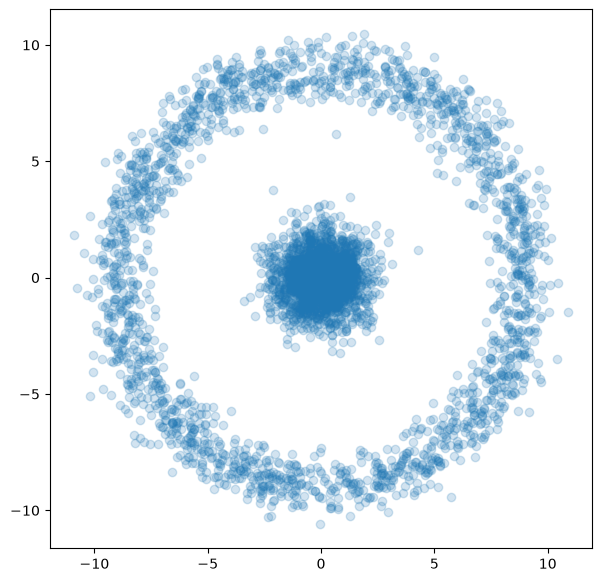

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(sample[:,0], sample[:,1], alpha=0.2)
plt.show()

### Eine geometrische Transformation

In [3]:
# this produces the same as meshgrid, but is more explicit:
ticks = 20
frames = 70
x = np.outer(np.linspace(-12, 12, ticks), np.ones(ticks))
y = x.copy().T # transpose
rbf_surface_in_time =   np.linspace(0, 1, frames).reshape(1, 1, -1) \
                      * ((x**2 + y**2).reshape(ticks, ticks, 1))

In [4]:
import matplotlib.animation as animation
from IPython import display as ipydisplay
import io, base64

def init(ax):
    ax.clear()
    ax.set_xlim(-12, 12)
    ax.set_ylim(-12, 12)
    ax.set_zlim( -1, 350)
    ax.set_zticklabels([])
    
def update_surface(i, ax):
    init(ax)
    ax.view_init(10, 15+i)
    ax.plot_surface(x, y, rbf_surface_in_time[:,:,i])

def update_data(i, ax):
    init(ax)
    ax.view_init(10, 15+i)
    ax.scatter(sample[:,0], sample[:,1],
               2*i/frames * (sample[:,0]**2 + sample[:,1]**2),
               marker='.', s=50)
    
def plot_ani(func=update_surface):
    fig = plt.figure(figsize=(7, 7))
    fig.set_size_inches(9, 9)
    ax = plt.axes(projection='3d')
    ani = animation.FuncAnimation(fig, func, fargs=(ax,), interval=100,
                              frames=np.hstack([np.arange(frames),np.arange(frames)[::-1]]))
    video = ani.to_html5_video()
    # Zusätzlich das letzte Bild als PNG ausgeben: der Web-Export zeigt das Video,
    # der PDF-Export (der kein HTML kann) verwendet das Standbild.
    png = io.BytesIO()
    fig.savefig(png, format='png')
    ipydisplay.display({'text/html': video,
                        'image/png': base64.b64encode(png.getvalue()).decode('ascii')},
                       raw=True)
    plt.close()

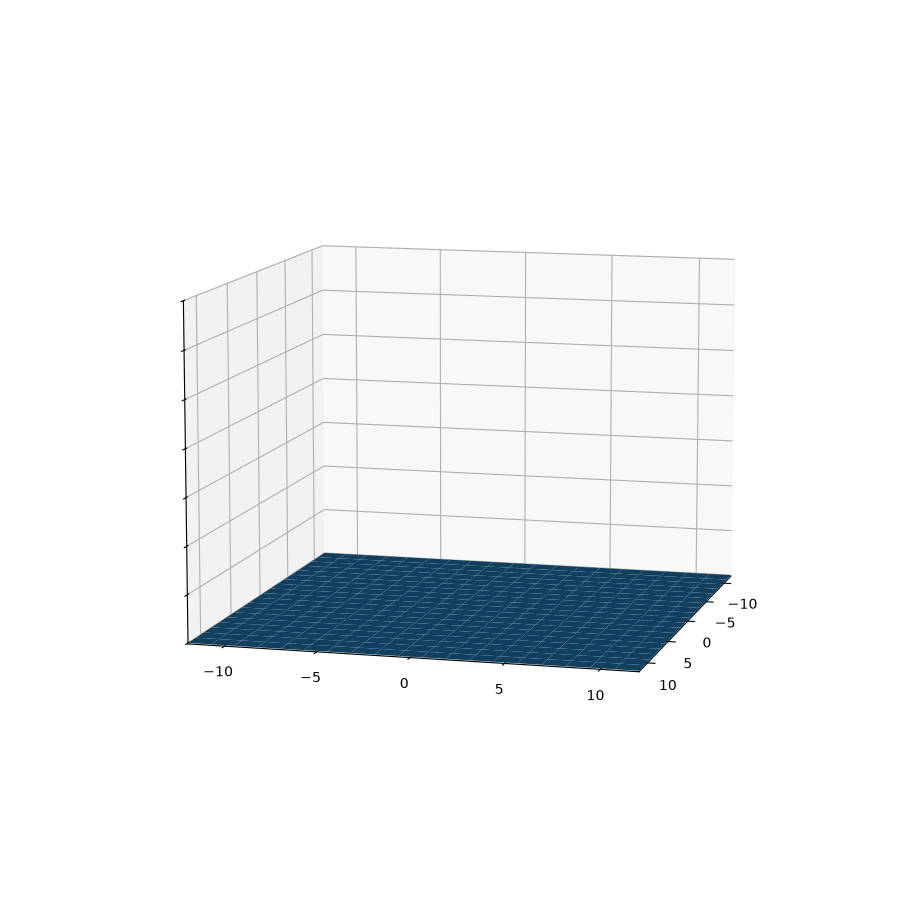

In [5]:
plot_ani(update_surface)

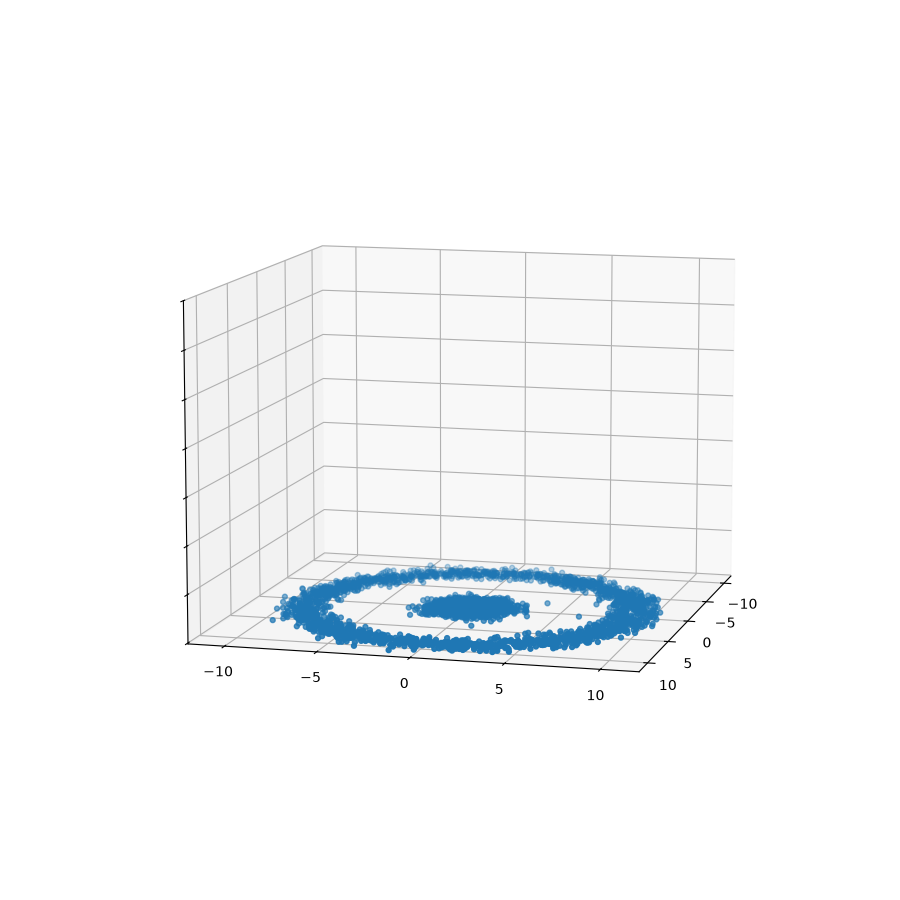

In [6]:
plot_ani(update_data)

Diese so transformierten Daten lassen sich nun mit 2-Means clustern!

### k-Means im transformierten Raum

In [7]:
def radial(x, y):
    """Quadrierter Abstand von (x,y) zum Ursprung: eine einzelne Koordinate
    der Feature-Abbildung φ, die wir weiter unten allgemein einführen."""
    return x**2 + y**2

xs, ys = sample[:,0], sample[:,1] 
zs = radial(xs, ys)

from sklearn.cluster import KMeans
kmeans_fit = KMeans(n_clusters=2, n_init=1).fit(np.stack([xs,ys,zs]).T)

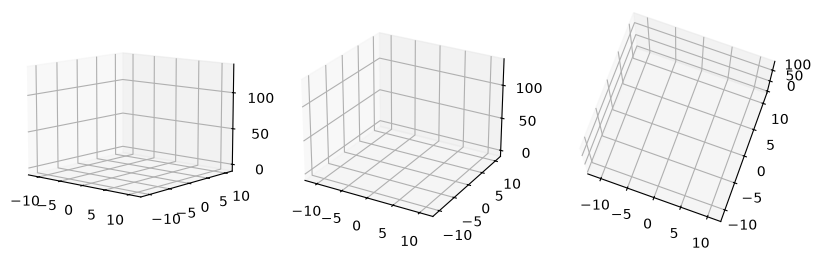

In [8]:
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(331, projection='3d')
ax2 = fig.add_subplot(332, projection='3d')
ax3 = fig.add_subplot(333, projection='3d')
for axis in (ax, ax2, ax3):
    axis.scatter(xs, ys, zs,
                 alpha=0.02, c=kmeans_fit.labels_,
                 cmap='brg')
ax.view_init(elev=10., azim=-50)
ax2.view_init(elev=25., azim=-60)
ax3.view_init(elev=75., azim=-70)
plt.show()

Wir können auch nur die k-Means-Berechnung in diesem größeren Raum (mit dem radialen Feature $x^2+y^2$) stattfinden lassen, die Labels dann mitnehmen und in unseren 'alten' zweidimensionalen Plot darstellen:

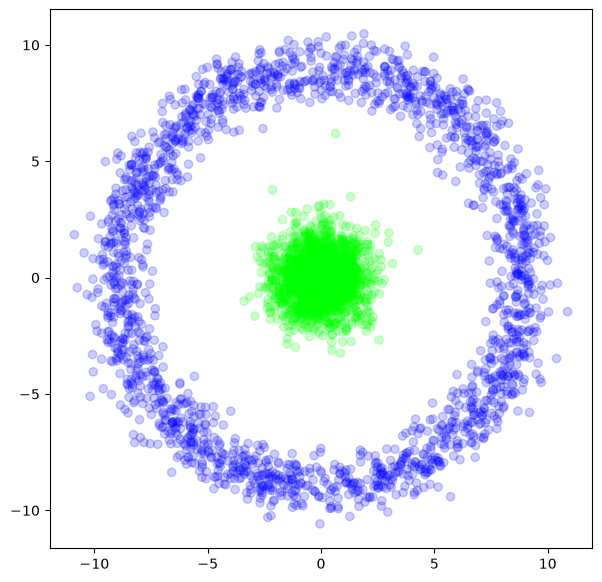

In [9]:
fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(sample[:,0], sample[:,1], alpha=0.2,
           c=kmeans_fit.labels_,
           cmap='brg')
plt.show()

### Was wir wirklich brauchten

Im k-Means-Verfahren werden die ganze Zeit *Abstände* gemessen. Es ist daher translations- und rotationsinvariant. Wenn wir außerdem nicht unsere Daten transformieren, sondern lediglich beim Messen der Abstände den Abstandsbegriff aus dem transformierten Raum verwenden, könnte das, je nach Transformation, weniger rechenintensiv sein.

Auch andere Verfahren, wie z.B. k-Nearest Neighbours und Support Vector Machines (was wir beides nicht besprochen haben) beruhen nur auf Abstandsmessungen.

## Daten durch Abstände beschreiben

```{admonition} Beispiel
Gegeben zwei Punkte $A, B$ in der Ebene, lassen sich diese durch ihre Koordinaten beschreiben.
Alternativ kann man sich das Datum des Abstands $d(A, B)$ merken und den Datensatz $(A, B)$ damit bis auf Translation und Rotation zurückgewinnen.
```

```{admonition} Beispiel
Gegeben drei Punkte $A, B, C$ im dreidimensionalen Raum, lassen sich diese durch ihre Koordinaten beschreiben.
Alternativ kann man sich das Datum der Abstände $d(A, B),\ d(B, C),\ d(A, C)$ merken und den Datensatz $(A, B, C)$ damit bis auf Translation und Rotation zurückgewinnen.
```

Der Kernel-Trick besteht nun darin, die Daten $x_i$ nicht durch die symmetrische Matrix $d(x_i, x_j)$ zu beschreiben, sondern durch eine andere Funktion $\kappa(x_i, x_j)$, die die gleiche Rolle spielt wie eine Abstandsmessung in einem transformierten Koordinatensystem.

Der euklidische Abstand ist

$$
d(a,b) = \lVert b - a \rVert = \sqrt{\langle b-a , b-a \rangle} = \sqrt{(b-a)^T (b-a)}
$$

Wenn man eine lineare Transformation $M$ anwendet auf die Daten, so berechnet man danach

$$
d(Ma, Mb)^2 = \lVert Mb - Ma \rVert^2 = \lVert M(b - a) \rVert^2 = \langle M(b-a), M(b-a) \rangle = (b-a)^T M^T M (b-a)
$$

sodass wir für eine Abstandsmessung im transformierten Raum eigentlich gar nicht $Ma$ und $Mb$ ausrechnen müssen, sondern 'nur' $M^TM$ ziemlich oft anwenden. Wenn wir Glück haben, ist das einfacher.

Oftmals ist ein guter Abstandsbegriff auch das Skalarprodukt $\langle a, b\rangle$ selbst bzw. $\langle Ma, Mb\rangle = b^T M^TM a$.

Nebenbemerkung, um das zu erläutern: Wir können auch ausrechnen, dass
$$
{\lVert b-a \rVert}^2 = \langle b-a, b-a\rangle = \langle b,b\rangle - 2\langle a, b\rangle + \langle a, a\rangle = {\lVert a \rVert}^2 + {\lVert b \rVert}^2 -2\langle a, b\rangle
$$
was für normierte Vektoren $a,b$ (also ${\lVert a \rVert} = 1$ und${\lVert b \rVert} = 1$) zeigt, dass es einen engen Zusammenhang zwischen $\langle a, b\rangle = {\lVert a \rVert}{\lVert b \rVert}\cos(\measuredangle(a,b)) = \cos(\measuredangle(a,b))$ und $d(a,b) = \sqrt{2}\sqrt{1-\langle a, b\rangle}$ gibt.

Von der linearen Situation abstrahiert man nun, und lässt eine beliebige Abbildung in einen Vektorraum mit Skalarprodukt zu.

## Kernel

```{admonition} Definition
Eine Abbildung $\kappa \colon \mathcal{X} \times \mathcal{X} \to \mathbb{R}$ heißt **Kernel**, wenn es einen Vektorraum $F$ mit Skalarprodukt $\langle,\rangle$ gibt sowie eine Abbildung $\phi \colon \mathcal{X} \to F$ sodass $\kappa(x,y) = \langle \phi(x),\ \phi(y) \rangle$ für alle $x,y \in \mathcal{X}$ gilt.
Der Vektorraum $F$ heißt **Feature-Raum** und $\phi$ die Feature-Abbildung.
```

Man muss bei einem Kernel den Raum $F$ und die Abbildung $\phi$ gar nicht kennen, weil für symmetrische positiv definite Funktionen $\kappa \colon \mathcal{X} \times \mathcal{X} \to \mathbb{R}$ stets eine Konstruktion $\phi \colon \mathcal{X} \to F$ existiert, sodass $\kappa$ damit als Kernel dargestellt werden kann (*Satz von Mercer*).

Man spricht auch von einem **Mercer**-Kernel und nennt allgemeiner Funktionen $\kappa$, die nicht notwendig positiv definit oder symmetrisch sind ebenfalls **Kernel-Funktionen**.

Man spricht allgemein von der **Kernel-Methode**, wenn man einen Algorithmus so umformuliert, dass er nur mit den Skalarprodukten der Feature-Vektoren arbeitet und ersetzt dann dieses durch eine Kernelfunktion.

### Gausssche Kernel

```{admonition} Definition
Kernel der Form

$$
\kappa(x,y) = e^{\left(-\dfrac{\lVert x - y \rVert^2}{2\sigma^2}\right)}
$$

heißen **Gauss-Kernel** mit Parameter $\gamma = \frac{1}{2\sigma^2}$.
Alternativ spricht man auch vom **quadrierten Exponentialkernel** oder dem **quadratischen Exponentialkernel** oder dem **radialen Basisfunktionskernel**.
```

Man beachte, dass wir hier nicht $(x-\mu)$ mit $(y-\mu)$ vergleichen müssen, weil diese die gleiche Differenz $x-y$ haben. Die sonst übliche Normierung entfällt ebenfalls, weil wir es nicht mit Wahrscheinlichkeiten zu tun haben, sondern mit einem Abstandsbegriff.

In [10]:
from sklearn.metrics.pairwise import rbf_kernel

k = rbf_kernel(sample, gamma=None)
# from the scikit-learn documentation:
# gamma: If None, defaults to 1.0 / n_features.

k

array([[1.00000000e+00, 2.35834400e-04, 2.34045005e-29, ...,
        2.40938682e-18, 3.06045881e-19, 3.64273927e-16],
       [2.35834400e-04, 1.00000000e+00, 3.52042608e-43, ...,
        7.01320593e-18, 5.46299575e-18, 1.39572356e-13],
       [2.34045005e-29, 3.52042608e-43, 1.00000000e+00, ...,
        3.99398494e-15, 1.15545519e-16, 2.13557232e-20],
       ...,
       [2.40938682e-18, 7.01320593e-18, 3.99398494e-15, ...,
        1.00000000e+00, 9.01017418e-01, 2.86696420e-01],
       [3.06045881e-19, 5.46299575e-18, 1.15545519e-16, ...,
        9.01017418e-01, 1.00000000e+00, 3.92528836e-01],
       [3.64273927e-16, 1.39572356e-13, 2.13557232e-20, ...,
        2.86696420e-01, 3.92528836e-01, 1.00000000e+00]],
      shape=(4000, 4000))

Nur, was fängt man jetzt mit dem Kernel an?

Zum Beispiel lineare Regression mit Ridge Regularisierung:

In [11]:
from sklearn.kernel_ridge import KernelRidge

# target variable is #cluster,
# given how we created the sample, it simply is:
y = np.hstack([np.zeros(len(sample)//2),np.ones(len(sample)//2)])

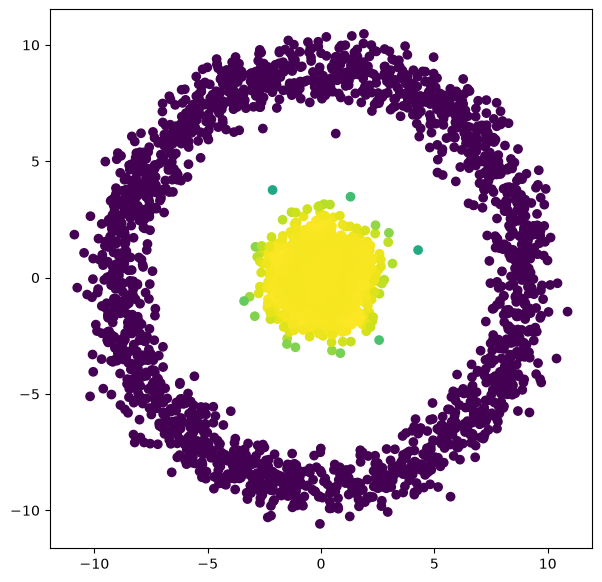

In [12]:
clf = KernelRidge(kernel="precomputed")

clf.fit(k, y)
y_pred = clf.predict(k)

fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(sample[:,0], sample[:,1], c=y_pred)
plt.show()

## Kernel PCA

Bei der Hauptachsentransformation werden die Eigenvektoren der Kovarianzmatrix berechnet. Man kann die Daten auch zuerst nichtlinear transformieren, bevor man das tut - oder aber die entsprechend transformierte Kovarianzmatrix verwenden.

In [13]:
from sklearn.decomposition import PCA, KernelPCA

pca = PCA(n_components=2)
kernel_pca = KernelPCA(
    n_components=None, kernel="rbf", gamma=0.2, alpha=2.5
)
# these parameters gamma, alpha needed some manual tweaking!

In [14]:
sample_pca = pca.fit_transform(sample)

In [15]:
# The following may need more than 16 GB of RAM,
# if the sample is large, so we're not going there:
#sample_kernel_pca = kernel_pca.fit_transform(sample)

# Keep it calm, train_size=2000 suffices:
from sklearn.model_selection import train_test_split
smaller_sample, remainder_sample, smaller_y, remainder_y \
  = train_test_split(sample, y_pred, train_size=2000)

sample_kernel_pca = kernel_pca.fit_transform(smaller_sample)

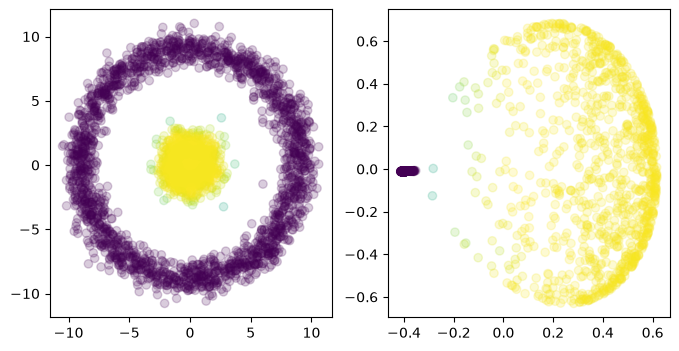

In [16]:
fig, axs = plt.subplots(ncols = 2, figsize=(8,4))
axs[0].scatter(sample_pca[:,0], sample_pca[:,1],
               c=y_pred, alpha=0.2)
axs[1].scatter(sample_kernel_pca[:,0], sample_kernel_pca[:,1],
               c=smaller_y, alpha=0.2)
plt.show()

Genau genommen vergrößert Kernel-PCA zunächst die Anzahl an Dimensionen (mit der nichtlinearen Feature-Abbildung), um sie daraufhin linear auf Hauptkomponenten zu transformieren, sodass man wiederum unwichtige Dimensionen wegschmeißen kann. Die erste Hauptkomponente im Feature-Raum entspricht im ursprünglichen Beobachtungsraum keiner Geraden mehr, sondern einer nichtlinearen Kurve.